# Step 6 — Final Evaluation

Consolidated results for classification and detection, plus error analysis.

In [3]:
import json, numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

ROOT    = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL")
reports = ROOT / "reports"

cm      = np.array(json.loads((reports / "eval_finetuned.json").read_text())["confusion_matrix"])
classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

mistakes = []
for i in range(4):
    for j in range(4):
        if i != j and cm[i, j] > 0:
            mistakes.append((cm[i, j], classes[i], classes[j]))
mistakes.sort(reverse=True)

print("Top classification errors (true → predicted):")
for count, t, p in mistakes[:4]:
    print(f"  {count:3d} images: True {t:12s} → predicted as {p}")

Top classification errors (true → predicted):
   23 images: True Meningioma   → predicted as Glioma
   21 images: True Meningioma   → predicted as Pituitary
    4 images: True Glioma       → predicted as Pituitary
    3 images: True No Tumor     → predicted as Pituitary


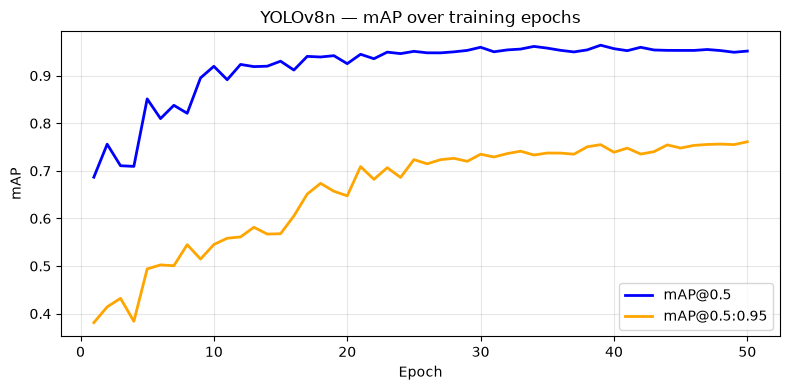

In [2]:
import pandas as pd

csv_path = ROOT / "runs" / "yolo_brain_mri" / "results.csv"
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

plt.figure(figsize=(8, 4))
plt.plot(df["epoch"], df["metrics/mAP50(B)"],    label="mAP@0.5",      color="blue",   lw=2)
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", color="orange", lw=2)
plt.title("YOLOv8n — mAP over training epochs")
plt.xlabel("Epoch"); plt.ylabel("mAP")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(reports / "yolo_training_curve.png", dpi=120, bbox_inches="tight")
plt.show()

## Final evaluation summary

### Classification (EfficientNet-B0 fine-tuned, test split 711 imgs)
- **Accuracy: 91.70%**  |  Macro F1: **92.20%**
- Strongest: No Tumor (F1 0.967)  |  Weakest: Meningioma (F1 0.867)
- Dominant error: Meningioma → Glioma misclassification (visually similar on some slices)

### Detection (YOLOv8n, test split 711 imgs)
- **mAP@0.5: 0.955**  |  mAP@0.5:0.95: 0.739
- Strongest: Meningioma (mAP50 0.990)  |  Weakest: Glioma (mAP50 0.902, recall 0.814)
- No Tumor = negative class (no GT boxes), correctly excluded from mAP

### Deployable artifacts
- `models/best_model.keras` — classifier (winner)
- `models/yolo_brain_mri_best.pt` — detector
- Both small enough for Docker + Streamlit (Step 8/9)